In [1058]:
from pyod.utils.data import generate_data
import matplotlib.pyplot as plt
import numpy as np

# EX 1

In [1059]:
X_train, X_test, y_train, y_test = generate_data(n_train=400, n_test=100, n_features=2, contamination=0.1, train_only=False, offset=10, behaviour='new', random_state=None, n_nan=0, n_inf=0)

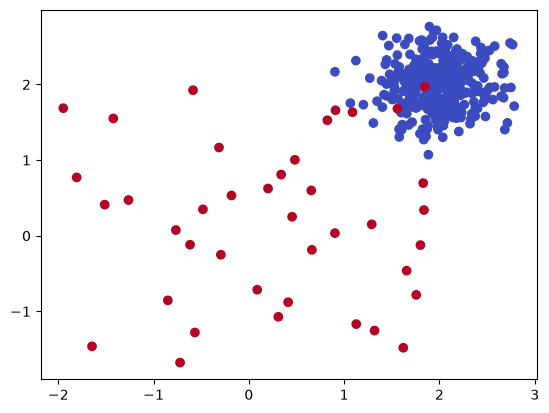

In [1060]:
scatter = plt.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap="coolwarm")
plt.show()

# EX 2

In [1061]:
from pyod.models.knn import KNN
from sklearn.metrics import confusion_matrix, roc_curve, auc, balanced_accuracy_score

In [1062]:
clf = KNN(contamination=0.1)
clf.fit(X_train)

y_train_pred = clf.labels_
y_test_pred = clf.predict(X_test)

Train confusion matrix
True Positives (TP): 37
True Negatives (TN): 357
False Positives (FP): 3
False Negatives (FN): 3
Balanced Accuracy: 0.9583333333333334


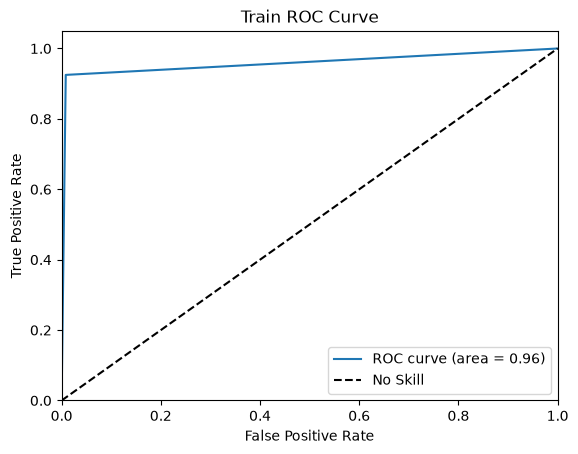

In [1063]:
cm_train = confusion_matrix(y_train, y_train_pred)
TN, FP, FN, TP = cm_train.ravel()
balanced_accuracy = balanced_accuracy_score(y_train, y_train_pred)
print("Train confusion matrix")
print(f"True Positives (TP): {TP}")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"Balanced Accuracy: {balanced_accuracy}")

fpr, tpr, thresholds = roc_curve(y_train, y_train_pred) 
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Train ROC Curve')
plt.legend()
plt.show()


Test confusion matrix
True Positives (TP): 10
True Negatives (TN): 90
False Positives (FP): 0
False Negatives (FN): 0
Balanced Accuracy: 1.0


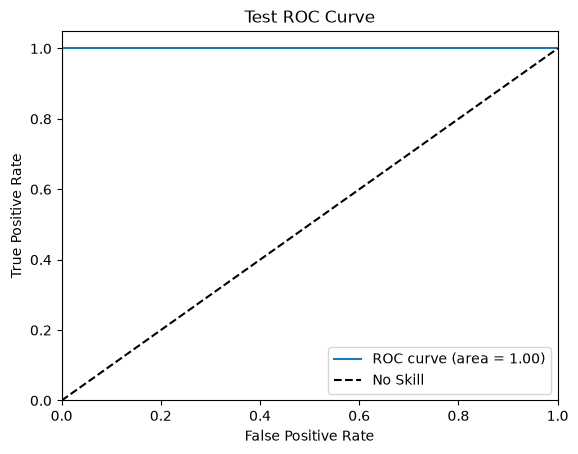

In [1064]:
cm_test = confusion_matrix(y_test, y_test_pred)
TN, FP, FN, TP = cm_test.ravel()
balanced_accuracy = balanced_accuracy_score(y_test, y_test_pred)

print("Test confusion matrix")
print(f"True Positives (TP): {TP}")
print(f"True Negatives (TN): {TN}")
print(f"False Positives (FP): {FP}")
print(f"False Negatives (FN): {FN}")
print(f"Balanced Accuracy: {balanced_accuracy}")

fpr, tpr, thresholds = roc_curve(y_test, y_test_pred) 
roc_auc = auc(fpr, tpr)

# Plot the ROC curve
plt.figure()  
plt.plot(fpr, tpr, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], 'k--', label='No Skill')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Test ROC Curve')
plt.legend()
plt.show()


# EX 3

In [1065]:
X_train, y_train = generate_data(n_train=1000, n_features=1, contamination=0.1, train_only=True)

In [1066]:
mean = np.mean(X_train)
std = np.std(X_train)
z_scores = np.abs((X_train - mean) / std).flatten()

In [1067]:
threshold = np.quantile(z_scores, 0.9)
y_pred = (z_scores >= threshold).astype(int)

balanced_accuracy = balanced_accuracy_score(y_train, y_pred)

print(f"Balanced Accuracy: {balanced_accuracy}")

Balanced Accuracy: 0.9055555555555556


# EX 4

In [1068]:
u = np.array([3.0, 4.0])
covariance_matrix = np.array([[4.0, -1.0], [-1.0, 2.0]])

L = np.linalg.cholesky(covariance_matrix)

In [1069]:
x_inliers = np.random.normal(0, 1, size=(900, 2))
y_inliers = np.dot(x_inliers, L.T) + u

x_outliers = np.random.normal(5, 1, size=(100, 2)) 
y_outliers = np.dot(x_outliers, L.T) + u

X_train = np.concatenate([y_inliers, y_outliers], axis=0)
y_train = np.concatenate([np.zeros(900), np.ones(100)], axis=0)

In [1070]:
mean = np.mean(X_train, axis=0)
inv_cov = np.linalg.inv(np.cov(X_train, rowvar=False))
diff = X_train - mean
z_scores = np.sqrt(np.sum(np.dot(diff, inv_cov) * diff, axis=1))

threshold = np.quantile(z_scores, 0.9)
y_pred = (z_scores >= threshold).astype(int)

balanced_accuracy = balanced_accuracy_score(y_train, y_pred)

print(f"Balanced Accuracy: {balanced_accuracy}")

Balanced Accuracy: 0.8944444444444445
